# Credit risk: predicting next-month default
Business question: Can customer repayment history improve prioritization of a limited account-review budget?

This is a historical educational analysis, not a deployable lending model. The target is the supplied default label; realized losses and intervention effects are unavailable. We compare ranking, probability quality, review capacity, and explicitly hypothetical financial outcomes.

Source: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients (Yeh, 2009; CC BY 4.0). Amounts are NT dollars; April–September 2005 history. Preliminary whole-file inspection preceded this notebook; subsequent model selection uses training data only.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss, precision_score, recall_score
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
SEED=42
ROOT=Path.cwd()
for folder in ['figures','reports']: (ROOT/folder).mkdir(exist_ok=True)
df=pd.read_excel(ROOT/'default of credit card clients.xls',header=1,engine='xlrd')
df=df.rename(columns={'default payment next month':'default_next_month'})
assert df.ID.is_unique and set(df.default_next_month.unique())=={0,1}
print('Shape:',df.shape,'Missing cells:',df.isna().sum().sum())
print(df.default_next_month.value_counts())
print('Default rate:',df.default_next_month.mean())
print('Repeated profiles including outcome, excluding ID:',df.drop(columns='ID').duplicated().sum())

Shape: (30000, 25) Missing cells: 0
default_next_month
0    23364
1     6636
Name: count, dtype: int64
Default rate: 0.2212
Repeated profiles including outcome, excluding ID: 35


## Data preparation and split
ID is excluded. Unknown education/marriage codes and repayment codes are retained as categories; we do not invent their meanings. Negative bills are retained. No blanket outlier deletion is performed. Repeated profiles are retained because IDs are distinct, with a sensitivity check below.

60% training, 20% validation, 20% test, stratified by outcome. Cross-validation chooses the model using training data. Validation evaluates the fixed 10% review-capacity policy; the final test is evaluated afterward. This random split cannot establish future-period performance.

In [2]:
X=df.drop(columns=['ID','default_next_month']); y=df.default_next_month
X_train,X_other,y_train,y_other=train_test_split(X,y,test_size=.4,stratify=y,random_state=SEED)
X_valid,X_test,y_valid,y_test=train_test_split(X_other,y_other,test_size=.5,stratify=y_other,random_state=SEED)
print('Train / validation / test:',len(X_train),len(X_valid),len(X_test))
categorical=['SEX','EDUCATION','MARRIAGE','PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']
print({c:sorted(df[c].unique().tolist()) for c in categorical})

Train / validation / test: 18000 6000 6000
{'SEX': [1, 2], 'EDUCATION': [0, 1, 2, 3, 4, 5, 6], 'MARRIAGE': [0, 1, 2, 3], 'PAY_0': [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8], 'PAY_2': [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8], 'PAY_3': [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8], 'PAY_4': [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8], 'PAY_5': [-2, -1, 0, 2, 3, 4, 5, 6, 7, 8], 'PAY_6': [-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]}


## Training-data EDA
Show counts alongside rates: sparse categories have uncertain estimates. Associations do not establish causation. Positive repayment codes describe delays; -2 and 0 remain uninterpreted categories. Examine monetary distributions and correlations before interpreting coefficients.

       size      mean
PAY_0                
-2     1666  0.120648
-1     3383  0.169376
 0     8805  0.127655
 1     2245  0.334967
 2     1635  0.696636
 3      184  0.760870
 4       41  0.731707
 5       12  0.416667
 6        9  0.666667
 7        7  0.857143
 8       13  0.461538
        LIMIT_BAL       AGE  BILL_AMT1   PAY_AMT1
count    18000.00  18000.00   18000.00   18000.00
mean    167730.67     35.42   51473.41    5685.20
std     129767.65      9.16   73956.51   16898.34
min      10000.00     21.00 -165580.00       0.00
25%      50000.00     28.00    3594.00    1000.00
50%     140000.00     34.00   22344.50    2138.50
75%     240000.00     41.00   67571.00    5045.75
max    1000000.00     75.00  964511.00  873552.00


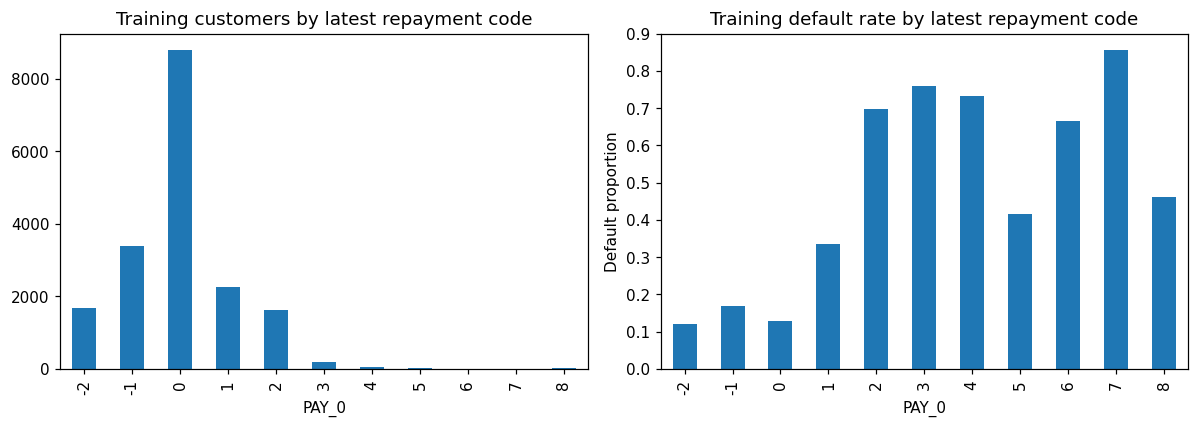

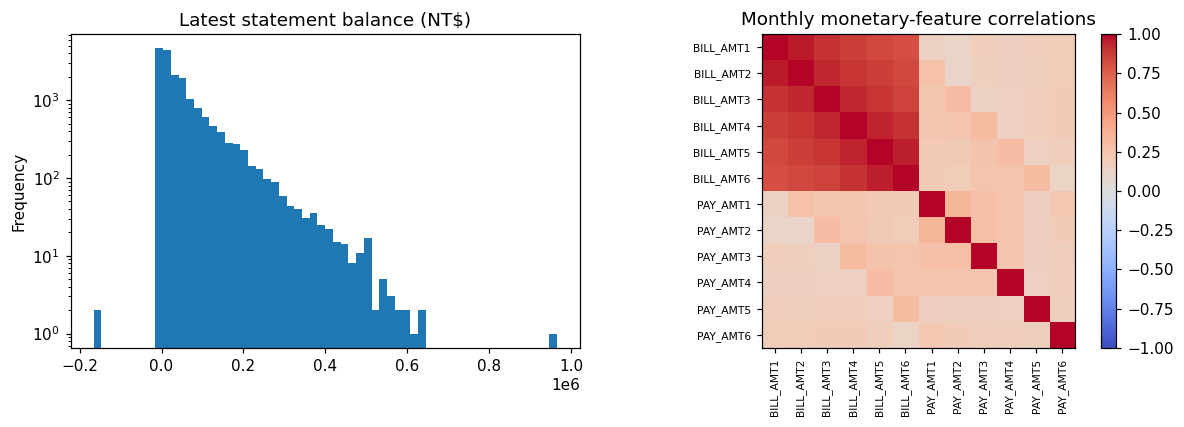

In [3]:
eda=X_train.assign(default=y_train)
rates=eda.groupby('PAY_0')['default'].agg(['size','mean'])
print(rates)
fig,axes=plt.subplots(1,2,figsize=(11,4))
rates['size'].plot.bar(ax=axes[0],title='Training customers by latest repayment code')
rates['mean'].plot.bar(ax=axes[1],title='Training default rate by latest repayment code')
axes[1].set_ylabel('Default proportion'); fig.tight_layout()
fig.savefig(ROOT/'figures/repayment_status.png',dpi=150); plt.show()
print(X_train[['LIMIT_BAL','AGE','BILL_AMT1','PAY_AMT1']].describe().round(2))
fig,axes=plt.subplots(1,2,figsize=(11,4))
X_train.BILL_AMT1.plot.hist(bins=60,ax=axes[0],title='Latest statement balance (NT$)')
axes[0].set_yscale('log')
im=axes[1].imshow(X_train.filter(regex='BILL_AMT|PAY_AMT').corr(),vmin=-1,vmax=1,cmap='coolwarm')
axes[1].set_title('Monthly monetary-feature correlations')
labels=X_train.filter(regex='BILL_AMT|PAY_AMT').columns
axes[1].set_xticks(range(len(labels))); axes[1].set_xticklabels(labels,rotation=90,fontsize=7)
axes[1].set_yticks(range(len(labels))); axes[1].set_yticklabels(labels,fontsize=7)
fig.colorbar(im,ax=axes[1]); fig.tight_layout(); fig.savefig(ROOT/'figures/distributions.png',dpi=150); plt.show()

## Models and training-only selection
An all-non-default classifier has zero default recall despite substantial accuracy. The probability baseline predicts the training prevalence. Logistic regression provides a simple baseline; random forest tests nonlinear effects. Both use the same original features. We deliberately keep this first version focused rather than add extensive feature engineering or tune against the holdout.

The primary ranking metric is average precision. Brier score and calibration are checked separately; ranking performance alone does not establish probability credibility. Preprocessing is fitted inside each training fold.

In [4]:
numeric=[c for c in X if c not in categorical]
prep=ColumnTransformer([('cat',OneHotEncoder(handle_unknown='ignore'),categorical),('num',StandardScaler(),numeric)])
models={
 'Prevalence baseline':DummyClassifier(strategy='prior'),
 'Logistic regression':Pipeline([('prep',prep),('model',LogisticRegression(max_iter=3000,C=1))]),
 'Random forest':Pipeline([('prep',prep),('model',RandomForestClassifier(n_estimators=150,max_depth=12,min_samples_leaf=20,random_state=SEED,n_jobs=2))])}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
cv_rows=[]
for name,model in models.items():
 scores=cross_validate(model,X_train,y_train,cv=cv,scoring={'ap':'average_precision','auc':'roc_auc','brier':'neg_brier_score'},n_jobs=1)
 cv_rows.append({'model':name,'average_precision':scores['test_ap'].mean(),'ap_fold_sd':scores['test_ap'].std(),'roc_auc':scores['test_auc'].mean(),'brier':-scores['test_brier'].mean()})
cv_results=pd.DataFrame(cv_rows).set_index('model')
print(cv_results.round(4)); cv_results.to_csv(ROOT/'reports/cross_validation.csv')
selected=cv_results.drop(index='Prevalence baseline').average_precision.idxmax()
for model in models.values(): model.fit(X_train,y_train)
print('Selected from training CV:',selected)

                     average_precision  ap_fold_sd  roc_auc   brier
model                                                              
Prevalence baseline             0.2212      0.0001   0.5000  0.1723
Logistic regression             0.5465      0.0104   0.7703  0.1353
Random forest                   0.5504      0.0114   0.7828  0.1347
Selected from training CV: Random forest


## Fixed operational policy and holdout evaluation
Review the highest-risk 10% of customers: this capacity assumption was fixed before evaluating validation or test results. Precision is the default rate among reviewed customers; recall is the fraction of all defaults captured. Lift divides review precision by the cohort default rate. The PAY_0 rule breaks equal-code ties using original row order, not outcomes.

The selected estimator stays trained on the 60% training set for this evaluation. No validation/test observations are used for refitting or calibration. If calibration is poor, financial conclusions remain provisional and a separately validated calibration pipeline is future work.

Validation:                      roc_auc  average_precision  ...  recall_at_10pct  lift_at_10pct
model                                            ...                                
Prevalence baseline   0.5000             0.2212  ...           0.1017         1.0173
Logistic regression   0.7547             0.5162  ...           0.2984         2.9842
Random forest         0.7743             0.5376  ...           0.2992         2.9917

[3 rows x 7 columns]
Test:                      roc_auc  average_precision  ...  recall_at_10pct  lift_at_10pct
model                                            ...                                
Prevalence baseline   0.5000             0.2212  ...           0.1078         1.0776
Logistic regression   0.7759             0.5585  ...           0.3165         3.1650
Random forest         0.7823             0.5647  ...           0.3173         3.1726

[3 rows x 7 columns]
Repayment rule recall at 10%: 0.31499623210248684
Expected random-selection recall: 10%


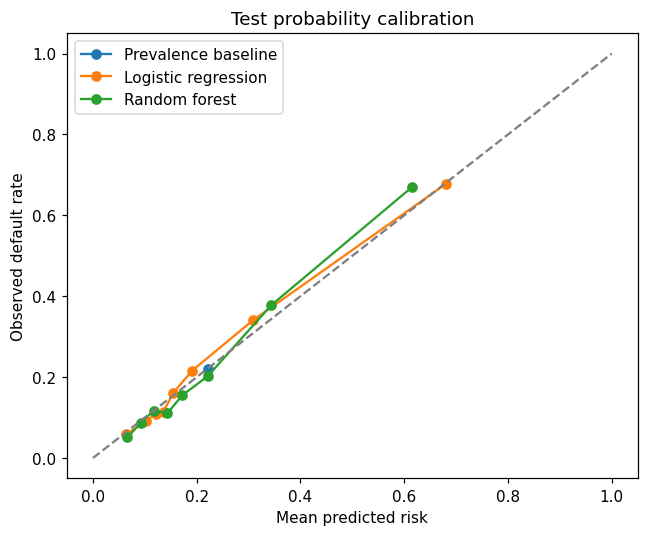

In [5]:
def top_mask(scores,fraction=.10):
 mask=np.zeros(len(scores),dtype=bool); mask[np.argsort(-np.asarray(scores),kind='stable')[:int(np.ceil(len(scores)*fraction))]]=True
 return mask
def evaluate(name,truth,p):
 mask=top_mask(p)
 return {'model':name,'roc_auc':roc_auc_score(truth,p),'average_precision':average_precision_score(truth,p),'brier':brier_score_loss(truth,p),'log_loss':log_loss(truth,p),'precision_at_10pct':np.asarray(truth)[mask].mean(),'recall_at_10pct':np.asarray(truth)[mask].sum()/np.asarray(truth).sum(),'lift_at_10pct':np.asarray(truth)[mask].mean()/np.asarray(truth).mean()}
validation=pd.DataFrame([evaluate(n,y_valid,m.predict_proba(X_valid)[:,1]) for n,m in models.items()]).set_index('model')
print('Validation:',validation.round(4)); validation.to_csv(ROOT/'reports/validation_metrics.csv')
test_probs={n:m.predict_proba(X_test)[:,1] for n,m in models.items()}
test_metrics=pd.DataFrame([evaluate(n,y_test,p) for n,p in test_probs.items()]).set_index('model')
print('Test:',test_metrics.round(4)); test_metrics.to_csv(ROOT/'reports/test_metrics.csv')
p=test_probs[selected]; selected_mask=top_mask(p)
rule_mask=top_mask(X_test.PAY_0.to_numpy())
print('Repayment rule recall at 10%:',y_test.to_numpy()[rule_mask].sum()/y_test.sum())
print('Expected random-selection recall: 10%')
fig,ax=plt.subplots(figsize=(6,5))
for name,pred in test_probs.items():
 observed,predicted=calibration_curve(y_test,pred,n_bins=8,strategy='quantile')
 ax.plot(predicted,observed,'o-',label=name)
ax.plot([0,1],[0,1],'--',color='gray'); ax.set(xlabel='Mean predicted risk',ylabel='Observed default rate',title='Test probability calibration'); ax.legend(); fig.tight_layout(); fig.savefig(ROOT/'figures/calibration.png',dpi=150); plt.show()
rng=np.random.RandomState(SEED); boot=[]
for _ in range(300):
 idx=rng.randint(0,len(y_test),len(y_test)); truth=y_test.to_numpy()[idx]
 boot.append([roc_auc_score(truth,p[idx]),average_precision_score(truth,p[idx])])
print('95% bootstrap intervals, ROC-AUC / AP:',np.quantile(boot,[.025,.975],axis=0))

## Interpretation, subgroup checks, and repeated-profile sensitivity
Permutation importance measures reduction in average precision when one original feature is shuffled. Correlated histories can distribute importance; predictive relationships are not causal. Subgroup comparisons are descriptive audits, not certification of fairness. A bootstrap interval reflects sampling variation, not geographic or temporal transportability.

In [6]:
importance=permutation_importance(models[selected],X_valid,y_valid,scoring='average_precision',n_repeats=3,random_state=SEED,n_jobs=1)
imp=pd.Series(importance.importances_mean,index=X.columns).sort_values(ascending=False)
print(imp.head(10)); imp.to_csv(ROOT/'reports/permutation_importance.csv')
audit=X_test[['SEX','AGE']].copy(); audit['actual']=y_test; audit['predicted']=p; audit['reviewed']=selected_mask
print(audit.groupby('SEX').agg(n=('actual','size'),default_rate=('actual','mean'),mean_predicted=('predicted','mean'),review_rate=('reviewed','mean')))
train_profiles=set(pd.util.hash_pandas_object(X_train,index=False).tolist())
overlap=pd.util.hash_pandas_object(X_test,index=False).isin(train_profiles).to_numpy()
print('Test predictor profiles also present in training:',overlap.sum())
print('Metrics excluding overlapping profiles:',evaluate(selected,y_test[~overlap],p[~overlap]))

PAY_0        0.149105
PAY_2        0.028196
PAY_AMT3     0.008418
LIMIT_BAL    0.007936
PAY_AMT1     0.007095
PAY_4        0.006021
PAY_AMT2     0.005829
PAY_6        0.005790
BILL_AMT1    0.005776
PAY_3        0.005552
dtype: float64
        n  default_rate  mean_predicted  review_rate
SEX                                                 
1    2372      0.241147        0.229545     0.097386
2    3628      0.208104        0.215872     0.101709
Test predictor profiles also present in training: 13
Metrics excluding overlapping profiles: {'model': 'Random forest', 'roc_auc': np.float64(0.7823229730237817), 'average_precision': np.float64(0.5647889146621626), 'brier': np.float64(0.13376736899283667), 'log_loss': 0.4275433696262168, 'precision_at_10pct': np.float64(0.7011686143572621), 'recall_at_10pct': np.float64(0.31746031746031744), 'lift_at_10pct': np.float64(3.1730132230966954)}


## Financial scenario analysis — assumed, not realized savings
Expected loss = PD × assumed exposure × LGD. Net intervention benefit = expected loss × assumed avoidable fraction − review cost. The data do not measure EAD, recovery, intervention effectiveness, or realized losses. Positive latest balances are used solely as an exposure proxy; negative balances are clipped to zero for this proxy, not altered in modeling.

Compare equal-capacity policies. The random baseline below is its mathematical expectation. Both prediction-based and observed-outcome scenario values are shown: observed labels still do not reveal actual loss amounts or causal intervention effects. No policy is an automatic approval or rejection recommendation.

Illustrative base assumptions only:          policy  assumed_lgd  assumed_loss_avoided_fraction  cost_ntd  reviews  predicted_scenario_net_ntd  outcome_based_scenario_net_ntd
     Model risk          0.6                            0.1       300    600.0                1.243886e+06                     1504894.200
 Repayment rule          0.6                            0.1       300    600.0                1.275724e+06                     1567834.020
Random expected          0.6                            0.1       300    600.0                1.980703e+05                      216677.904


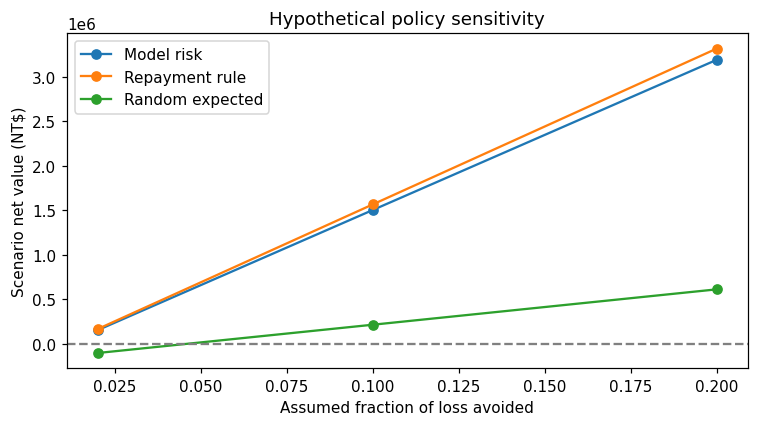

In [7]:
exposure=np.maximum(X_test.BILL_AMT1.to_numpy(),0)
truth=y_test.to_numpy(); rng=np.random.RandomState(SEED)
policies={'Model risk':selected_mask,'Repayment rule':rule_mask,'Random expected':np.full(len(p),selected_mask.mean())}
financial=[]
for lgd in [.3,.6,.9]:
 for effectiveness in [.02,.10,.20]:
  for cost in [100,300,1000]:
   for policy,weights in policies.items():
    financial.append({'policy':policy,'assumed_lgd':lgd,'assumed_loss_avoided_fraction':effectiveness,'cost_ntd':cost,'reviews':np.sum(weights),'predicted_scenario_net_ntd':np.sum(weights*(p*exposure*lgd*effectiveness-cost)),'outcome_based_scenario_net_ntd':np.sum(weights*(truth*exposure*lgd*effectiveness-cost))})
financial=pd.DataFrame(financial); financial.to_csv(ROOT/'reports/financial_scenarios.csv',index=False)
base=financial[(financial.assumed_lgd==.6)&(financial.assumed_loss_avoided_fraction==.1)&(financial.cost_ntd==300)]
print('Illustrative base assumptions only:',base.to_string(index=False))
fig,ax=plt.subplots(figsize=(7,4))
for policy in policies:
 subset=financial[(financial.policy==policy)&(financial.assumed_lgd==.6)&(financial.cost_ntd==300)]
 ax.plot(subset.assumed_loss_avoided_fraction,subset.outcome_based_scenario_net_ntd,marker='o',label=policy)
ax.axhline(0,color='gray',linestyle='--'); ax.set(xlabel='Assumed fraction of loss avoided',ylabel='Scenario net value (NT$)',title='Hypothetical policy sensitivity'); ax.legend(); fig.tight_layout(); fig.savefig(ROOT/'figures/financial_sensitivity.png',dpi=150); plt.show()
summary={'selected_model':selected,'default_rate':float(y.mean()),'test_metrics':test_metrics.loc[selected].to_dict(),'bootstrap_95pct_auc_ap':np.quantile(boot,[.025,.975],axis=0).tolist(),'repayment_rule_recall_at_10pct':float(truth[rule_mask].sum()/truth.sum()),'overlapping_test_profiles':int(overlap.sum())}
(ROOT/'reports/results.json').write_text(json.dumps(summary,indent=2))

## Conclusion and next steps
Use the generated metric tables to assess whether the selected model improves review prioritization over the rule baseline. Evaluate calibration before treating probabilities as financial inputs. Financial outputs are scenario-dependent, not evidence of actual savings.

A next iteration could compare engineered features, calibrated estimators, and models excluding demographic inputs, using new training-only protocols. Before operational use, require a later-period cohort, validated target definitions and category codes, actual exposure/recovery data, and a measured intervention pilot.
The random forest captured only three more defaults than the repayment rule among 600 reviewed test accounts (421 versus 418). Logistic regression captured 420. These small differences do not establish a meaningful operational advantage for the more complex model; prefer a simple policy unless further validation justifies complexity.
